# Predicting power-system load type

This notebook predicts `Load_Type` (`Light_Load`, `Medium_Load`, `Maximum_Load`) from one year of 15-minute industrial electricity readings.

The company brief asks for five things: preprocessing, exploratory data analysis, feature engineering, model selection, and evaluation. Two evaluation rules are fixed. The test set is the last month, December 2018. The reported metrics are accuracy, precision, recall, and F1-score.

Model choice uses **macro-F1 on November**, the last month that is still inside the training period. December is scored once, after the choice is locked. Macro-F1 gives the three classes equal weight. Accuracy is still reported, but light load is common enough that accuracy alone rewards predicting light load every time.

Run the notebook from top to bottom. Figures are saved in `figures/`, and the metric tables are saved in `outputs/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    from IPython import get_ipython
except ImportError:  # pragma: no cover
    get_ipython = lambda: None

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 120

RANDOM_STATE = 42
LABELS = ["Light_Load", "Medium_Load", "Maximum_Load"]
SHORT = {
    "Light_Load": "Light",
    "Medium_Load": "Medium",
    "Maximum_Load": "Maximum",
}
PALETTE = {
    "Light_Load": "#4C78A8",
    "Medium_Load": "#F58518",
    "Maximum_Load": "#E45756",
}
METER_COLUMNS = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
]
COLUMN_LABELS = {
    "Usage_kWh": "Usage (kWh)",
    "Lagging_Current_Reactive.Power_kVarh": "Lagging reactive power",
    "Leading_Current_Reactive_Power_kVarh": "Leading reactive power",
    "CO2(tCO2)": "CO2 (tCO2)",
    "Lagging_Current_Power_Factor": "Lagging power factor",
    "Leading_Current_Power_Factor": "Leading power factor",
    "NSM": "NSM (seconds from midnight)",
    "hour": "Hour",
    "day_of_week": "Day of week",
    "is_weekend": "Weekend",
    "tod_sin": "Time of day (sine)",
    "tod_cos": "Time of day (cosine)",
    "dow_sin": "Day of week (sine)",
    "dow_cos": "Day of week (cosine)",
    "month_sin": "Month (sine)",
    "month_cos": "Month (cosine)",
    "apparent_lagging": "Apparent power, lagging",
    "apparent_leading": "Apparent power, leading",
    "usage_prev": "Usage, previous interval",
    "usage_trail_1h": "Usage, trailing hour",
    "nsm_was_corrupt": "NSM was corrupt",
    "pf_lag_was_corrupt": "Lagging power factor was corrupt",
    "pf_lead_was_corrupt": "Leading power factor was corrupt",
    "usage_was_missing": "Usage was missing",
    "leading_kvarh_was_missing": "Leading reactive power was missing",
    "leading_pf_was_missing": "Leading power factor was missing",
}
TREE_COLUMNS = ["Usage_kWh", "hour", "day_of_week"]
IMPUTE_COLUMNS = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "apparent_lagging",
    "apparent_leading",
    "usage_prev",
    "usage_trail_1h",
]
FEATURE_COLUMNS = IMPUTE_COLUMNS + [
    "NSM",
    "hour",
    "day_of_week",
    "is_weekend",
    "tod_sin",
    "tod_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "nsm_was_corrupt",
    "pf_lag_was_corrupt",
    "pf_lead_was_corrupt",
    "usage_was_missing",
    "leading_kvarh_was_missing",
    "leading_pf_was_missing",
]
MODEL_NAMES = [
    "Majority class",
    "Shallow decision tree",
    "Logistic regression",
    "Random forest, balanced weights",
    "Histogram gradient boosting",
    "Histogram gradient boosting, balanced weights",
]
# Near-ties prefer the simpler model. The order below is that simplicity rank.
SIMPLICITY = {name: rank for rank, name in enumerate(MODEL_NAMES)}
HGB_PARAMS = dict(
    max_iter=200,
    learning_rate=0.08,
    max_depth=6,
    min_samples_leaf=20,
    l2_regularization=0.1,
    random_state=RANDOM_STATE,
    early_stopping=False,
)


def find_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent]
    if "__file__" in globals():
        script_dir = Path(__file__).resolve().parent
        candidates.extend([script_dir, script_dir.parent])
    for candidate in candidates:
        if (candidate / "data" / "load_data.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find data/load_data.csv from the working directory.")


def show_df(frame: pd.DataFrame) -> None:
    ipython = get_ipython()
    if ipython is not None:
        from IPython.display import display

        display(frame)
    else:
        print(frame.to_string())
        print()


def save_figure(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    if get_ipython() is not None:
        plt.show()
    else:
        plt.close(fig)


ROOT = find_root()
DATA_PATH = ROOT / "data" / "load_data.csv"
FIGURES = ROOT / "figures"
OUTPUTS = ROOT / "outputs"
FIGURES.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)
print(f"Project root: {ROOT}")

Project root: D:\assignment-2 1


## 1. Load the file and audit it

Dates in the file are day-first (`01-01-2018 00:15`). The audit below is done on the file in its original order, before any repair.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw["timestamp"] = pd.to_datetime(raw["Date_Time"], format="%d-%m-%Y %H:%M")

print(f"Rows: {len(raw):,}")
print(f"Columns: {list(raw.columns)}")
print(f"Timestamps parsed: {raw['timestamp'].notna().all()}")
print(f"First file row: {raw['timestamp'].iloc[0]}")
print(f"Last file row: {raw['timestamp'].iloc[-1]}")
print(f"True earliest: {raw['timestamp'].min()}")
print(f"True latest: {raw['timestamp'].max()}")

backward_steps = int((raw["timestamp"].diff().dt.total_seconds() < 0).sum())
print(f"Steps that go backward in file order: {backward_steps}")
print("Load type counts:")
show_df(raw["Load_Type"].value_counts().rename("rows").to_frame())

missing_counts = raw[METER_COLUMNS].isna().sum().rename("blank_rows").to_frame()
missing_counts["share"] = missing_counts["blank_rows"] / len(raw)
print("Blank measurements:")
show_df(missing_counts)

expected_nsm = raw["timestamp"].dt.hour * 3600 + raw["timestamp"].dt.minute * 60
nsm_mismatch = raw["NSM"].notna() & ((raw["NSM"] - expected_nsm).abs() >= 1)
nsm_outside_day = raw["NSM"].notna() & ((raw["NSM"] < 0) | (raw["NSM"] >= 86400))
print(f"NSM values that disagree with the clock: {int(nsm_mismatch.sum()):,}")
print(f"NSM values outside a real day: {int(nsm_outside_day.sum()):,}")
print("Examples of NSM that do not match the clock:")
nsm_examples = raw.loc[nsm_mismatch, ["Date_Time", "NSM"]].head(5).copy()
nsm_examples["NSM from clock"] = expected_nsm.loc[nsm_examples.index].to_numpy()
show_df(nsm_examples)

for column in ["Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"]:
    outside = raw[column].notna() & ((raw[column] < 0) | (raw[column] > 100))
    print(
        f"{column} outside 0–100: {int(outside.sum()):,} "
        f"(max {raw[column].max():.1f})"
    )

duplicate_times = raw["timestamp"].duplicated(keep=False)
print(f"Rows sharing a timestamp: {int(duplicate_times.sum())}")
show_df(
    raw.loc[
        duplicate_times,
        ["Date_Time", "Usage_kWh", "Lagging_Current_Power_Factor", "Load_Type"],
    ]
)

Rows: 35,041
Columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type', 'timestamp']
Timestamps parsed: True
First file row: 2018-01-01 00:15:00
Last file row: 2018-12-31 20:00:00
True earliest: 2018-01-01 00:00:00
True latest: 2018-12-31 23:45:00
Steps that go backward in file order: 365
Load type counts:


,rows
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


Blank measurements:


,blank_rows,share
Usage_kWh,1559,0.044491
Lagging_Current_Reactive.Power_kVarh,876,0.024999
Leading_Current_Reactive_Power_kVarh,1156,0.032990
CO2(tCO2),455,0.012985
Lagging_Current_Power_Factor,350,0.009988
Leading_Current_Power_Factor,1471,0.041979
NSM,455,0.012985


NSM values that disagree with the clock: 3,414
NSM values outside a real day: 1,773
Examples of NSM that do not match the clock:


,Date_Time,NSM,NSM from clock
2,01-01-2018 00:45,8070.880991,2700
7,01-01-2018 02:00,16589.736450,7200
13,01-01-2018 03:30,36574.178080,12600
14,01-01-2018 03:45,35294.963040,13500
38,01-01-2018 09:45,85881.718200,35100


Lagging_Current_Power_Factor outside 0–100: 3,226 (max 300.0)
Leading_Current_Power_Factor outside 0–100: 2,685 (max 300.0)
Rows sharing a timestamp: 2


,Date_Time,Usage_kWh,Lagging_Current_Power_Factor,Load_Type
35023,31-12-2018 20:00,4.14,100.00000,Light_Load
35040,31-12-2018 20:00,NaN,217.27347,Light_Load


## 2. Clean the measurements

Five repairs follow from the audit.

1. Sort by timestamp. Each day's midnight row is stored after 23:45, so the file jumps backward once a day.
2. At a duplicated timestamp, keep the row with a present usage and a lagging power factor inside 0–100. That rule keeps the physically consistent 31 December 2018 20:00 row and drops the row whose power factor is 217.
3. Replace `NSM` with seconds computed from the timestamp. The stored column disagrees with the clock thousands of times. `nsm_was_corrupt` remembers that the original value was blank or wrong.
4. Recompute power factor as `100 * kWh / sqrt(kWh² + kVarh²)` whenever usage and the matching reactive power are present and the denominator is not zero. A stored value outside 0–100, or more than one point away from this formula, is marked corrupt. Leftover impossible values are set to missing.
5. Keep a missingness flag for usage, leading reactive power, and leading power factor. Those are the fields that are blank most often. The flags are taken from the original file, before any repair.

CO2 is left as stored. The brief calls it ppm, and the column is named `CO2(tCO2)`. The values are small (median 0, maximum under 0.2), which matches tonnes rather than ppm. Nothing in the file supports rescaling it.

Zeros are left as zeros. A zero reading is a real idle meter, not a blank.

In [3]:
def physical_power_factor(usage: pd.Series, reactive: pd.Series) -> pd.Series:
    both_present = usage.notna() & reactive.notna()
    denominator = pd.Series(
        np.sqrt(usage.fillna(0).to_numpy() ** 2 + reactive.fillna(0).to_numpy() ** 2),
        index=usage.index,
    ).replace(0, np.nan)
    factor = 100 * usage.fillna(0) / denominator
    return factor.where(both_present)


def repair_power_factor(frame: pd.DataFrame, source: str, reactive: str, flag: str) -> None:
    rebuilt = physical_power_factor(frame["Usage_kWh"], frame[reactive])
    stored = frame[source]
    far_from_formula = stored.notna() & rebuilt.notna() & ((stored - rebuilt).abs() > 1)
    outside_range = stored.notna() & ((stored < 0) | (stored > 100))
    frame[flag] = (far_from_formula | outside_range).astype(int)
    frame[source] = rebuilt.where(rebuilt.notna(), stored)
    still_impossible = frame[source].notna() & ((frame[source] < 0) | (frame[source] > 100))
    frame.loc[still_impossible, source] = np.nan


def clean(frame: pd.DataFrame) -> pd.DataFrame:
    cleaned = frame.copy()
    cleaned["usage_was_missing"] = cleaned["Usage_kWh"].isna().astype(int)
    cleaned["leading_kvarh_was_missing"] = cleaned["Leading_Current_Reactive_Power_kVarh"].isna().astype(int)
    cleaned["leading_pf_was_missing"] = cleaned["Leading_Current_Power_Factor"].isna().astype(int)

    clock_nsm = cleaned["timestamp"].dt.hour * 3600 + cleaned["timestamp"].dt.minute * 60
    cleaned["nsm_was_corrupt"] = (
        cleaned["NSM"].isna() | ((cleaned["NSM"] - clock_nsm).abs() >= 1)
    ).astype(int)

    duplicated = cleaned["timestamp"].duplicated(keep=False)
    conflicts = cleaned.loc[duplicated].copy()
    kept_body = cleaned.loc[~duplicated].copy()
    if not conflicts.empty:
        usage_ok = conflicts["Usage_kWh"].notna()
        power_factor = conflicts["Lagging_Current_Power_Factor"]
        power_factor_ok = power_factor.notna() & power_factor.between(0, 100)
        conflicts["_keep_score"] = usage_ok.astype(int) + power_factor_ok.astype(int)
        conflicts = conflicts.sort_values(["timestamp", "_keep_score"], ascending=[True, False])
        kept_conflicts = conflicts.groupby("timestamp", as_index=False).head(1)
        kept_conflicts = kept_conflicts.drop(columns="_keep_score")
        cleaned = pd.concat([kept_body, kept_conflicts], ignore_index=True)
    else:
        cleaned = kept_body

    cleaned = cleaned.sort_values("timestamp").reset_index(drop=True)
    cleaned["NSM"] = (
        cleaned["timestamp"].dt.hour * 3600 + cleaned["timestamp"].dt.minute * 60
    ).astype(float)

    repair_power_factor(
        cleaned,
        "Lagging_Current_Power_Factor",
        "Lagging_Current_Reactive.Power_kVarh",
        "pf_lag_was_corrupt",
    )
    repair_power_factor(
        cleaned,
        "Leading_Current_Power_Factor",
        "Leading_Current_Reactive_Power_kVarh",
        "pf_lead_was_corrupt",
    )

    for source, reactive, target in [
        ("Lagging_Current_Reactive.Power_kVarh", "Lagging_Current_Reactive.Power_kVarh", "apparent_lagging"),
        ("Leading_Current_Reactive_Power_kVarh", "Leading_Current_Reactive_Power_kVarh", "apparent_leading"),
    ]:
        reactive_series = cleaned[reactive]
        usage = cleaned["Usage_kWh"]
        both_present = usage.notna() & reactive_series.notna()
        magnitude = pd.Series(
            np.sqrt(usage.fillna(0).to_numpy() ** 2 + reactive_series.fillna(0).to_numpy() ** 2),
            index=cleaned.index,
        )
        cleaned[target] = magnitude.where(both_present)

    minutes = cleaned["timestamp"].dt.hour * 60 + cleaned["timestamp"].dt.minute
    time_angle = 2 * np.pi * minutes / (24 * 60)
    cleaned["tod_sin"] = np.sin(time_angle)
    cleaned["tod_cos"] = np.cos(time_angle)
    cleaned["hour"] = cleaned["timestamp"].dt.hour
    cleaned["day_of_week"] = cleaned["timestamp"].dt.dayofweek
    cleaned["is_weekend"] = (cleaned["day_of_week"] >= 5).astype(int)
    month_angle = 2 * np.pi * (cleaned["timestamp"].dt.month - 1) / 12
    cleaned["month_sin"] = np.sin(month_angle)
    cleaned["month_cos"] = np.cos(month_angle)
    day_angle = 2 * np.pi * cleaned["day_of_week"] / 7
    cleaned["dow_sin"] = np.sin(day_angle)
    cleaned["dow_cos"] = np.cos(day_angle)

    # Trailing windows look backward only, including the current interval in the one-hour mean.
    cleaned["usage_prev"] = cleaned["Usage_kWh"].shift(1)
    cleaned["usage_trail_1h"] = cleaned["Usage_kWh"].rolling(4, min_periods=1).mean()
    return cleaned


cleaned = clean(raw)

expected_grid = pd.date_range("2018-01-01", "2018-12-31 23:45", freq="15min")
assert len(cleaned) == len(expected_grid) == 35040
assert cleaned["timestamp"].is_monotonic_increasing
assert not cleaned["timestamp"].duplicated().any()
assert cleaned["timestamp"].iloc[0] == expected_grid[0]
assert cleaned["timestamp"].iloc[-1] == expected_grid[-1]
assert (cleaned["timestamp"].diff().iloc[1:] == pd.Timedelta(minutes=15)).all()
clock_nsm = cleaned["timestamp"].dt.hour * 3600 + cleaned["timestamp"].dt.minute * 60
assert (cleaned["NSM"] == clock_nsm).all()
for power_column in ["Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"]:
    present = cleaned[power_column].dropna()
    assert present.between(0, 100).all()

december_20 = cleaned.loc[cleaned["timestamp"] == "2018-12-31 20:00"].iloc[0]
assert abs(december_20["Usage_kWh"] - 4.14) < 1e-6
assert december_20["Load_Type"] == "Light_Load"

print(f"Rows after cleaning: {len(cleaned):,}")
print(f"NSM values repaired: {int(cleaned['nsm_was_corrupt'].sum()):,}")
print(f"Lagging power factors repaired: {int(cleaned['pf_lag_was_corrupt'].sum()):,}")
print(f"Leading power factors repaired: {int(cleaned['pf_lead_was_corrupt'].sum()):,}")
print("Blanks remaining after the physical repairs, before median fill:")
show_df(cleaned[IMPUTE_COLUMNS].isna().sum().rename("blank_rows").to_frame())

Rows after cleaning: 35,040
NSM values repaired: 3,869
Lagging power factors repaired: 7,608
Leading power factors repaired: 4,575
Blanks remaining after the physical repairs, before median fill:


,blank_rows
Usage_kWh,1558
Lagging_Current_Reactive.Power_kVarh,876
Leading_Current_Reactive_Power_kVarh,1156
CO2(tCO2),455
Lagging_Current_Power_Factor,287
Leading_Current_Power_Factor,539
apparent_lagging,2388
apparent_leading,2665
usage_prev,1559
usage_trail_1h,0


## 3. Split by time

Training rows are January through November. December is the test set required by the brief.

November is the validation month used to choose the model. It is the last full month that can be held out without touching December. A random split would place 15:00 and 15:15 from the same day on opposite sides, and the score would look stronger than a new month really is.

Median fills are fit on the rows used for training in that step only. January–October medians are used while November is the validation month. January–November medians are used for the final December score.

In [4]:
train = cleaned.loc[cleaned["timestamp"] < "2018-12-01"].copy()
test = cleaned.loc[cleaned["timestamp"] >= "2018-12-01"].copy()

assert train["timestamp"].max() < test["timestamp"].min()
assert test["timestamp"].dt.month.eq(12).all()
assert len(train) == 32064
assert len(test) == 2976

print(f"Training rows (Jan–Nov): {len(train):,}")
print(f"Test rows (December): {len(test):,}")
print(f"Training ends: {train['timestamp'].max()}")
print(f"Test starts: {test['timestamp'].min()}")
print("Training class counts:")
show_df(train["Load_Type"].value_counts().rename("rows").reindex(LABELS).to_frame())


def median_impute(fit_frame: pd.DataFrame, other_frames: list[pd.DataFrame]) -> tuple[list[pd.DataFrame], pd.Series]:
    medians = fit_frame[IMPUTE_COLUMNS].median()
    filled = []
    for frame in other_frames:
        copy = frame.copy()
        copy[IMPUTE_COLUMNS] = copy[IMPUTE_COLUMNS].fillna(medians)
        filled.append(copy)
    return filled, medians

Training rows (Jan–Nov): 32,064
Test rows (December): 2,976
Training ends: 2018-11-30 23:45:00
Test starts: 2018-12-01 00:00:00
Training class counts:


,rows
Load_Type,
Light_Load,16328
Medium_Load,8992
Maximum_Load,6744


## 4. Explore the training months

These charts use January–November only. They answer four questions: whether one class dominates, whether usage alone separates the classes, whether the label is just a timetable, and whether the label stays put across neighboring intervals.

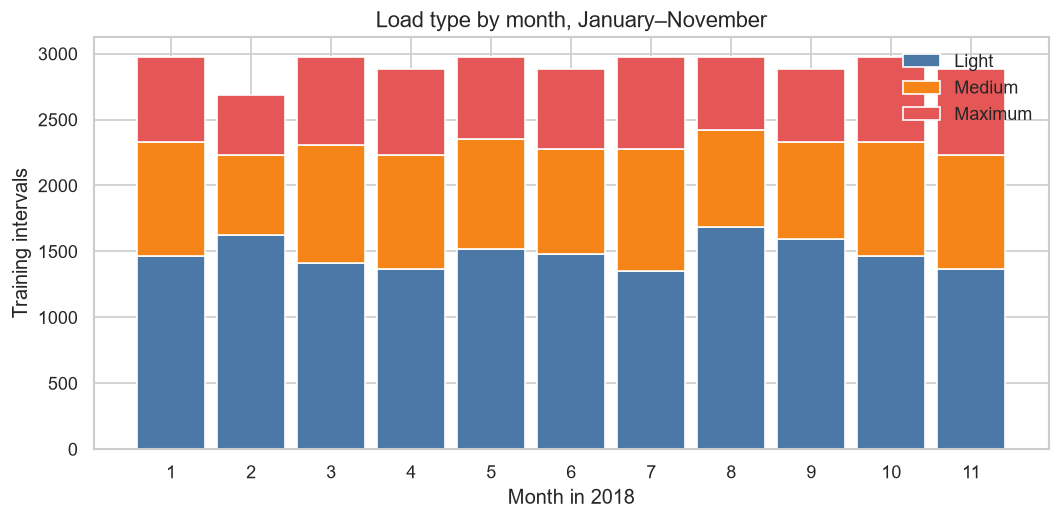

Usage level by load type, training months, blanks excluded from the quantiles:


,median_kWh,p90_kWh
Load_Type,,
Light_Load,3.35,17.17
Medium_Load,34.92,100.84
Maximum_Load,59.90,114.71


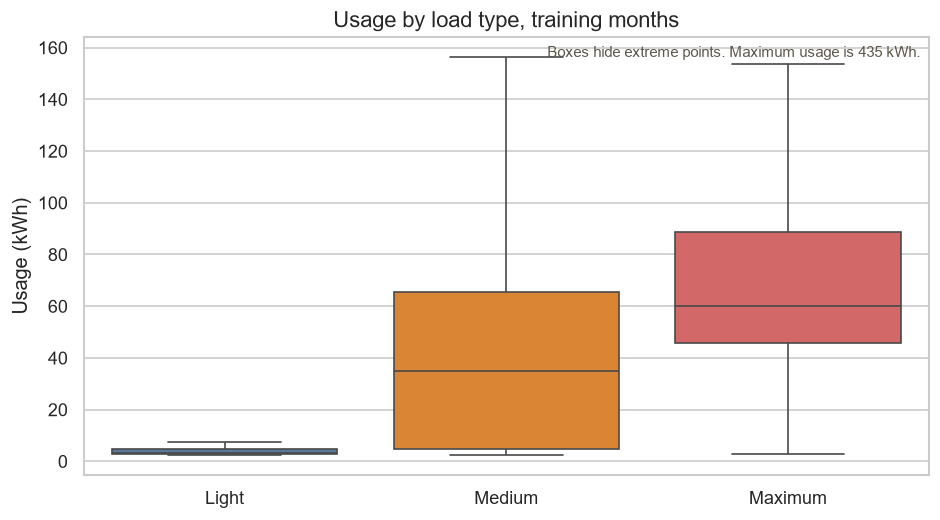

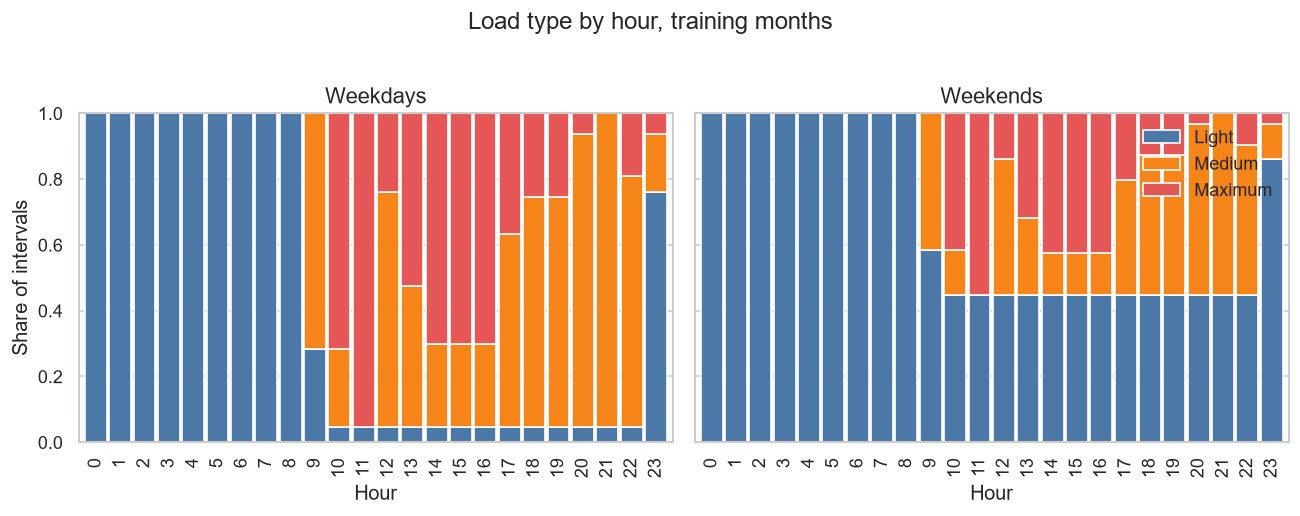

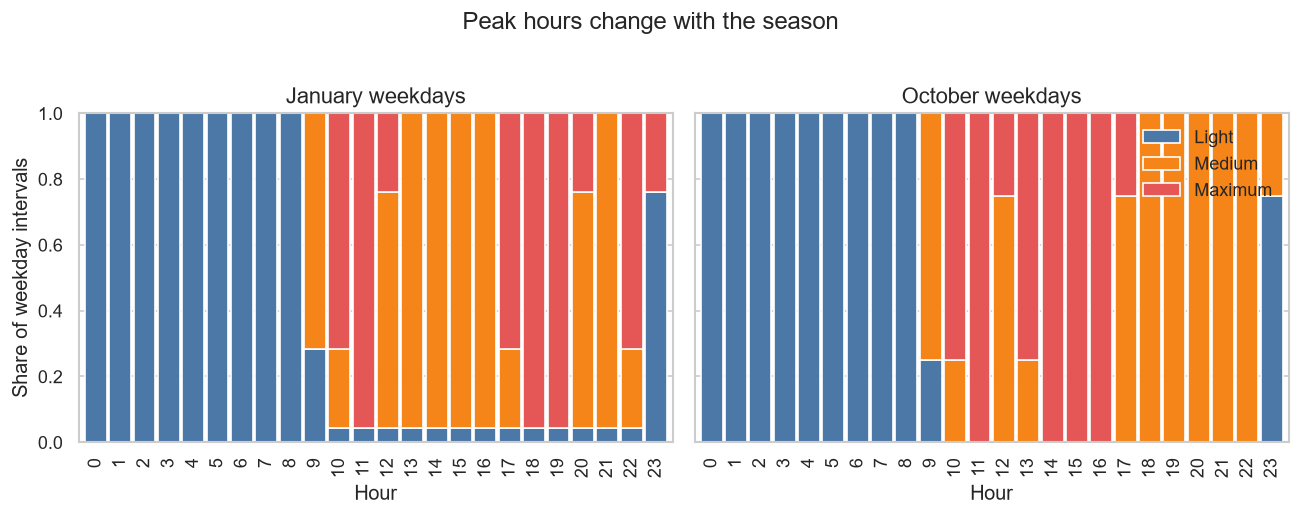

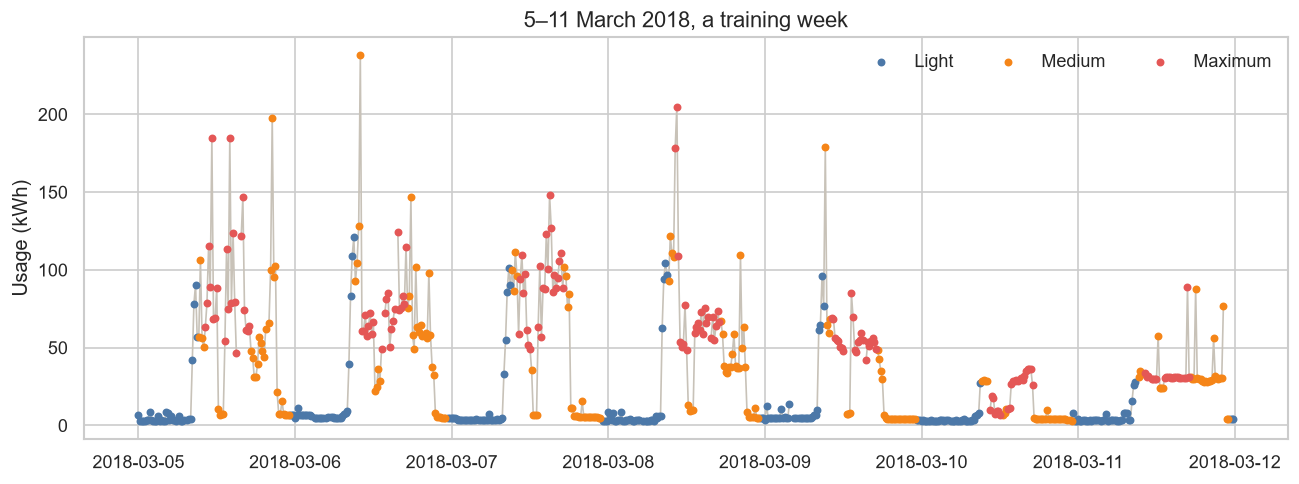

Original blank rate by class, training months:


,usage,leading reactive power,leading power factor
Load_Type,,,
Light_Load,0.043,0.033,0.043
Medium_Load,0.046,0.033,0.041
Maximum_Load,0.042,0.033,0.043


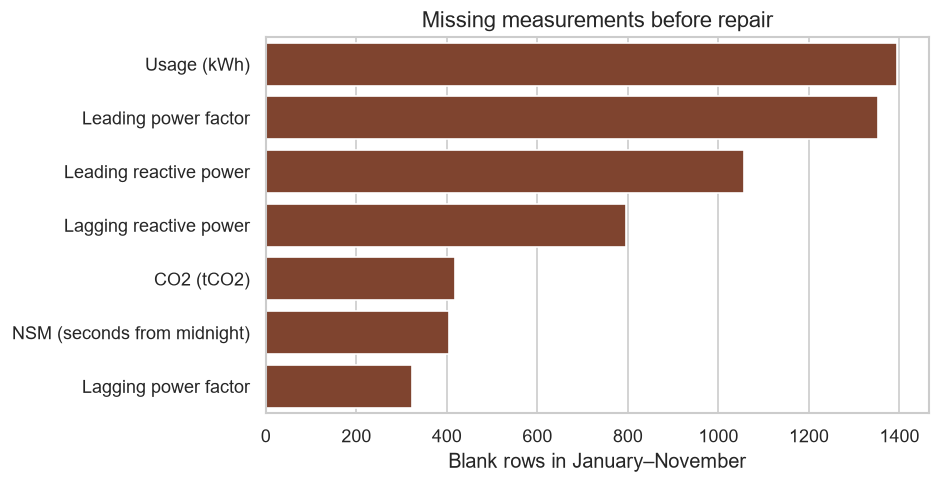

In [5]:
month_counts = (
    train.assign(month=train["timestamp"].dt.month)
    .pivot_table(index="month", columns="Load_Type", values="Usage_kWh", aggfunc="size", fill_value=0)
    .reindex(columns=LABELS)
)
fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(month_counts))
for label in LABELS:
    heights = month_counts[label].to_numpy()
    ax.bar(month_counts.index, heights, bottom=bottom, color=PALETTE[label], label=SHORT[label], width=0.85)
    bottom = bottom + heights
ax.set_xlabel("Month in 2018")
ax.set_ylabel("Training intervals")
ax.set_title("Load type by month, January–November")
ax.set_xticks(range(1, 12))
ax.legend(frameon=False)
save_figure(fig, FIGURES / "01_class_balance_by_month.png")

usage_quantiles = (
    train.groupby("Load_Type")["Usage_kWh"]
    .quantile([0.5, 0.9])
    .unstack()
    .rename(columns={0.5: "median_kWh", 0.9: "p90_kWh"})
    .reindex(LABELS)
)
print("Usage level by load type, training months, blanks excluded from the quantiles:")
show_df(usage_quantiles.round(2))

plot_usage = train.dropna(subset=["Usage_kWh"])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(
    data=plot_usage,
    x="Load_Type",
    y="Usage_kWh",
    order=LABELS,
    hue="Load_Type",
    hue_order=LABELS,
    palette=PALETTE,
    legend=False,
    showfliers=False,
    ax=ax,
)
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels([SHORT[label] for label in LABELS])
ax.set_xlabel("")
ax.set_ylabel("Usage (kWh)")
ax.set_title("Usage by load type, training months")
observed_max = plot_usage["Usage_kWh"].max()
ax.text(
    0.99,
    0.98,
    f"Boxes hide extreme points. Maximum usage is {observed_max:.0f} kWh.",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    color="#5c564c",
)
save_figure(fig, FIGURES / "02_usage_by_load.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, weekend, title in zip(axes, [0, 1], ["Weekdays", "Weekends"]):
    subset = train.loc[train["is_weekend"] == weekend]
    share = pd.crosstab(subset["hour"], subset["Load_Type"], normalize="index").reindex(columns=LABELS)
    share = share.reindex(range(24)).fillna(0)
    share.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[PALETTE[label] for label in LABELS],
        width=0.9,
        legend=False,
    )
    ax.set_title(title)
    ax.set_xlabel("Hour")
    ax.set_ylabel("Share of intervals" if weekend == 0 else "")
axes[1].legend([SHORT[label] for label in LABELS], frameon=False, loc="upper right")
fig.suptitle("Load type by hour, training months", y=1.02)
save_figure(fig, FIGURES / "03_load_by_hour.png")

# January and October are both inside the training period, and their weekday
# timetables differ. The all-year hour chart averages those seasons together.
def weekday_hour_share(frame: pd.DataFrame) -> pd.DataFrame:
    weekdays = frame.loc[frame["day_of_week"] < 5]
    share = pd.crosstab(weekdays["hour"], weekdays["Load_Type"], normalize="index")
    return share.reindex(columns=LABELS).reindex(range(24)).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, month, title in zip(
    axes,
    [1, 10],
    ["January weekdays", "October weekdays"],
):
    share = weekday_hour_share(train.loc[train["timestamp"].dt.month == month])
    share.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[PALETTE[label] for label in LABELS],
        width=0.9,
        legend=False,
    )
    ax.set_title(title)
    ax.set_xlabel("Hour")
axes[0].set_ylabel("Share of weekday intervals")
axes[1].legend([SHORT[label] for label in LABELS], frameon=False, loc="upper right")
fig.suptitle("Peak hours change with the season", y=1.02)
save_figure(fig, FIGURES / "03b_seasonal_hours.png")

week = train.loc[
    (train["timestamp"] >= "2018-03-05") & (train["timestamp"] < "2018-03-12")
].copy()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(week["timestamp"], week["Usage_kWh"], color="#c8c2b8", linewidth=1, zorder=1)
for label in LABELS:
    part = week.loc[week["Load_Type"] == label]
    ax.scatter(
        part["timestamp"],
        part["Usage_kWh"],
        s=14,
        color=PALETTE[label],
        label=SHORT[label],
        zorder=2,
    )
ax.set_title("5–11 March 2018, a training week")
ax.set_ylabel("Usage (kWh)")
ax.set_xlabel("")
ax.legend(frameon=False, ncol=3)
save_figure(fig, FIGURES / "04_example_week.png")

missing_by_class = []
for label in LABELS:
    subset = train.loc[train["Load_Type"] == label]
    rates = subset[["usage_was_missing", "leading_kvarh_was_missing", "leading_pf_was_missing"]].mean()
    rates["Load_Type"] = label
    missing_by_class.append(rates)
missing_class_table = pd.DataFrame(missing_by_class).set_index("Load_Type")
missing_class_table = missing_class_table.rename(
    columns={
        "usage_was_missing": "usage",
        "leading_kvarh_was_missing": "leading reactive power",
        "leading_pf_was_missing": "leading power factor",
    }
)
print("Original blank rate by class, training months:")
show_df(missing_class_table.round(3))

raw_train_stamp = raw["timestamp"] < "2018-12-01"
missing_plot = (
    raw.loc[raw_train_stamp, METER_COLUMNS]
    .isna()
    .sum()
    .rename_axis("column")
    .reset_index(name="blank_rows")
)
missing_plot["column"] = missing_plot["column"].map(COLUMN_LABELS)
missing_plot = missing_plot.sort_values("blank_rows", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=missing_plot, x="blank_rows", y="column", color="#8C3D22", ax=ax)
ax.set_xlabel("Blank rows in January–November")
ax.set_ylabel("")
ax.set_title("Missing measurements before repair")
save_figure(fig, FIGURES / "05_missingness.png")

## 5. Features the model is allowed to see

The hour chart that pools the whole training period hides a schedule change. On January weekdays, maximum load sits in late morning, late afternoon, and 22:00, and early afternoon is medium. On October weekdays, maximum load sits in the early afternoon, from 13:00 to 16:00, and the evening is medium. Both months are in the training data, so a later month can follow either timetable. The clock features have to be read together with the time of year.

Every feature is known at the timestamp of the row.

- Clock: rebuilt `NSM`, hour, day of week, weekend flag, and sine/cosine of time of day, day of week, and month. Sine and cosine place hour 23 next to hour 0, and December next to January. The raw month number is not used, because December would be a month number the training rows never contain.
- Meters: usage, both reactive powers, repaired power factors, and CO2.
- Apparent power: `sqrt(usage² + reactive²)` for lagging and leading current.
- Recent history: usage at the previous 15-minute stamp, and the mean of usage over the current interval plus the three before it. The window does not look forward.
- Data-quality flags: NSM repaired, power factor repaired, and the three original missingness flags.

Remaining blanks are filled with the training-period median. Zero is not used as a fill, because zero is a real measurement for reactive power, CO2, and sometimes usage. The median resists the long usage tail.

In [6]:
def balanced_sample_weight(y) -> np.ndarray:
    y = np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    weight_for_class = {label: len(y) / (len(classes) * count) for label, count in zip(classes, counts)}
    return np.array([weight_for_class[label] for label in y])


class LoadModel:
    """One entry on the model ladder. The inner estimator changes with the name."""

    def __init__(self, name: str):
        self.name = name
        self.mode_ = None
        self.model = None
        self.scaler = None

    def fit(self, frame: pd.DataFrame, y) -> "LoadModel":
        if self.name == "Majority class":
            self.mode_ = pd.Series(y).mode().iloc[0]
            return self
        if self.name == "Shallow decision tree":
            self.model = DecisionTreeClassifier(
                max_depth=3,
                min_samples_leaf=40,
                random_state=RANDOM_STATE,
            )
            self.model.fit(frame[TREE_COLUMNS], y)
            return self
        if self.name == "Logistic regression":
            self.scaler = StandardScaler()
            scaled = self.scaler.fit_transform(frame[FEATURE_COLUMNS])
            self.model = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            )
            self.model.fit(scaled, y)
            return self
        if self.name == "Random forest, balanced weights":
            self.model = RandomForestClassifier(
                n_estimators=200,
                max_depth=14,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )
            self.model.fit(frame[FEATURE_COLUMNS], y)
            return self
        if self.name == "Histogram gradient boosting":
            self.model = HistGradientBoostingClassifier(**HGB_PARAMS)
            self.model.fit(frame[FEATURE_COLUMNS], y)
            return self
        if self.name == "Histogram gradient boosting, balanced weights":
            self.model = HistGradientBoostingClassifier(**HGB_PARAMS)
            self.model.fit(frame[FEATURE_COLUMNS], y, sample_weight=balanced_sample_weight(y))
            return self
        raise ValueError(self.name)

    def predict(self, frame: pd.DataFrame) -> np.ndarray:
        if self.name == "Majority class":
            return np.full(len(frame), self.mode_)
        if self.name == "Shallow decision tree":
            return self.model.predict(frame[TREE_COLUMNS])
        if self.name == "Logistic regression":
            return self.model.predict(self.scaler.transform(frame[FEATURE_COLUMNS]))
        return self.model.predict(frame[FEATURE_COLUMNS])


def score_predictions(y_true, y_pred) -> dict:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    row = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0),
    }
    for label, prec, rec, f_score, supp in zip(LABELS, precision, recall, f1, support):
        short = SHORT[label].lower()
        row[f"precision_{short}"] = prec
        row[f"recall_{short}"] = rec
        row[f"f1_{short}"] = f_score
        row[f"support_{short}"] = int(supp)
    return row


def fit_window(fit_frame: pd.DataFrame, val_frame: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    (fit_filled, val_filled), _ = median_impute(fit_frame, [fit_frame, val_frame])
    y_fit = fit_filled["Load_Type"]
    y_val = val_filled["Load_Type"]
    rows = []
    fitted = {}
    for name in MODEL_NAMES:
        print(f"  fitting {name}")
        model = LoadModel(name)
        model.fit(fit_filled, y_fit)
        scored = score_predictions(y_val, model.predict(val_filled))
        scored["model"] = name
        rows.append(scored)
        fitted[name] = (model, val_filled, y_val)
    return pd.DataFrame(rows), fitted

## 6. Choose the model on earlier months

The ladder has six rungs.

- **Majority class** predicts the most common training label. This is the accuracy floor.
- **Shallow decision tree** uses only usage, hour, and day of week, with depth 3. This is the timetable-plus-usage rule, written as a model. It is not given class weights, so it shows the simple rule rather than a rebalanced one.
- **Logistic regression** uses the full feature set, standardized, with balanced class weights and L2 regularization. Coefficients are readable. A linear score has to be handed the clock interactions; it does not discover "high usage at 03:00 is different from high usage at 15:00" on its own as directly as a tree does.
- **Random forest with balanced class weights** is the close alternative. It learns thresholds and is stable, and later trees in a forest are not aimed at the remaining medium-versus-maximum mistakes.
- **Histogram gradient boosting**, with and without balanced sample weights, learns those corrections. Early stopping is off so the fit does not hold out a random slice of neighboring intervals. The two versions differ only in the weights. Balanced weights give each class the same total weight, which matters because light load is about half the rows.

k-nearest neighbors, a support vector machine, naive Bayes, and a neural network are not on the ladder. Distance-based neighbors are dominated by scale and by the filled medians. A kernel SVM is costly and harder to explain at this size. Naive Bayes assumes the meters are independent, and power factor is computed from usage and reactive power. A network does not beat a boosted tree on a table of this size, and it is harder to defend in a review. Inventing synthetic rows with SMOTE would break the 15-minute order the test is designed to check.

Each model is scored on September, October, and November, training only on months before that window. **November macro-F1 chooses the model.** If the top two November scores are within 0.005, the one with the better average across the three months is kept, and a remaining tie goes to the simpler model. December is not part of this choice.

In [7]:
windows = [
    ("September", "2018-09-01", "2018-10-01"),
    ("October", "2018-10-01", "2018-11-01"),
    ("November", "2018-11-01", "2018-12-01"),
]
window_tables = []
november_fitted = None
for window_name, start, end in windows:
    print(f"Validation window: {window_name}")
    fit_frame = train.loc[train["timestamp"] < start]
    val_frame = train.loc[(train["timestamp"] >= start) & (train["timestamp"] < end)]
    assert fit_frame["timestamp"].max() < val_frame["timestamp"].min()
    window_scores, fitted = fit_window(fit_frame, val_frame)
    window_scores.insert(0, "window", window_name)
    window_tables.append(window_scores)
    if window_name == "November":
        november_fitted = fitted

validation = pd.concat(window_tables, ignore_index=True)
validation.to_csv(OUTPUTS / "validation_scores.csv", index=False)

november = validation.loc[validation["window"] == "November"].sort_values(
    ["macro_f1", "model"], ascending=[False, True]
)
print("November scores, sorted by macro-F1:")
show_df(
    november[
        ["model", "accuracy", "macro_f1", "weighted_f1", "f1_light", "f1_medium", "f1_maximum"]
    ]
    .round(3)
    .reset_index(drop=True)
)

stability = validation.pivot(index="model", columns="window", values="macro_f1").reindex(MODEL_NAMES)
stability["three_month_mean"] = stability[["September", "October", "November"]].mean(axis=1)
print("Macro-F1 on each held-out month:")
show_df(stability.round(3))

ranked = november.reset_index(drop=True)
leader = ranked.iloc[0]
runner_up = ranked.iloc[1]
chosen_name = leader["model"]
if leader["macro_f1"] - runner_up["macro_f1"] < 0.005:
    leader_mean = stability.loc[leader["model"], "three_month_mean"]
    runner_mean = stability.loc[runner_up["model"], "three_month_mean"]
    if runner_mean > leader_mean + 1e-9:
        chosen_name = runner_up["model"]
    elif abs(runner_mean - leader_mean) <= 1e-9 and SIMPLICITY[runner_up["model"]] < SIMPLICITY[leader["model"]]:
        chosen_name = runner_up["model"]

print(f"Selected model: {chosen_name}")
print(
    "Selection used November macro-F1 only. "
    f"November macro-F1 for the selected model: {stability.loc[chosen_name, 'November']:.3f}."
)

Validation window: September
  fitting Majority class
  fitting Shallow decision tree
  fitting Logistic regression


  fitting Random forest, balanced weights


  fitting Histogram gradient boosting


  fitting Histogram gradient boosting, balanced weights


Validation window: October
  fitting Majority class
  fitting Shallow decision tree
  fitting Logistic regression


...

November scores, sorted by macro-F1:


,model,accuracy,macro_f1,weighted_f1,f1_light,f1_medium,f1_maximum
0,Histogram gradient boosting,0.685,0.600,0.686,0.981,0.485,0.333
1,"Random forest, balanced weights",0.685,0.599,0.685,0.980,0.483,0.333
2,"Histogram gradient boosting, balanced weights",0.681,0.598,0.684,0.977,0.485,0.331
3,Logistic regression,0.655,0.578,0.655,0.929,0.435,0.369
4,Shallow decision tree,0.606,0.532,0.617,0.915,0.383,0.299
5,Majority class,0.475,0.215,0.306,0.644,0.000,0.000


Macro-F1 on each held-out month:


window,November,October,September,three_month_mean
model,,,,
Majority class,0.215,0.220,0.237,0.224
Shallow decision tree,0.532,0.872,0.801,0.735
Logistic regression,0.578,0.909,0.838,0.775
"Random forest, balanced weights",0.599,0.986,0.951,0.845
Histogram gradient boosting,0.600,0.991,0.947,0.846
"Histogram gradient boosting, balanced weights",0.598,0.987,0.949,0.845


Selected model: Histogram gradient boosting
Selection used November macro-F1 only. November macro-F1 for the selected model: 0.600.


## 7. Fit on January–November and score December once

Every model is refit on January–November and scored on December so the baselines sit in the same table. Those December numbers are not used to change the selected model. Medians and the logistic scaler are fit on January–November only.

Permutation importance is computed on November, using the model that was trained on January–October. Shuffling a feature on the validation month shows how much November macro-F1 depends on it, without looking at December.

Refitting on January–November for the December comparison
  fitting Majority class
  fitting Shallow decision tree
  fitting Logistic regression


  fitting Random forest, balanced weights


  fitting Histogram gradient boosting


  fitting Histogram gradient boosting, balanced weights


December scores. The selected model was chosen before these numbers were computed:


,model,selected,accuracy,macro_f1,weighted_f1,f1_light,f1_medium,f1_maximum
0,Majority class,False,0.586,0.246,0.433,0.739,0.000,0.000
1,Shallow decision tree,False,0.605,0.495,0.637,0.867,0.326,0.293
2,Logistic regression,False,0.665,0.550,0.685,0.903,0.388,0.360
3,"Random forest, balanced weights",False,0.960,0.957,0.960,0.967,0.946,0.957
4,Histogram gradient boosting,True,0.962,0.958,0.961,0.968,0.942,0.965
5,"Histogram gradient boosting, balanced weights",False,0.963,0.959,0.962,0.969,0.945,0.965


December classification report for the selected model:
              precision    recall  f1-score   support

  Light_Load      0.947     0.990     0.968      1744
 Medium_Load      0.991     0.898     0.942       704
Maximum_Load      0.979     0.953     0.965       528

    accuracy                          0.962      2976
   macro avg      0.972     0.947     0.958      2976
weighted avg      0.963     0.962     0.961      2976

Permutation importance on November


Features that move November macro-F1 when shuffled:


,feature,importance_mean,importance_std
0,NSM,0.1286,0.0116
1,usage_trail_1h,0.0781,0.0023
2,tod_cos,0.0033,0.0007
3,tod_sin,0.0033,0.0014
4,Lagging_Current_Reactive.Power_kVarh,0.0014,0.0005
5,apparent_leading,0.0011,0.0001
6,Leading_Current_Power_Factor,0.0011,0.0002
7,Usage_kWh,0.0011,0.0003
8,apparent_lagging,0.0010,0.0004
9,CO2(tCO2),0.0008,0.0003


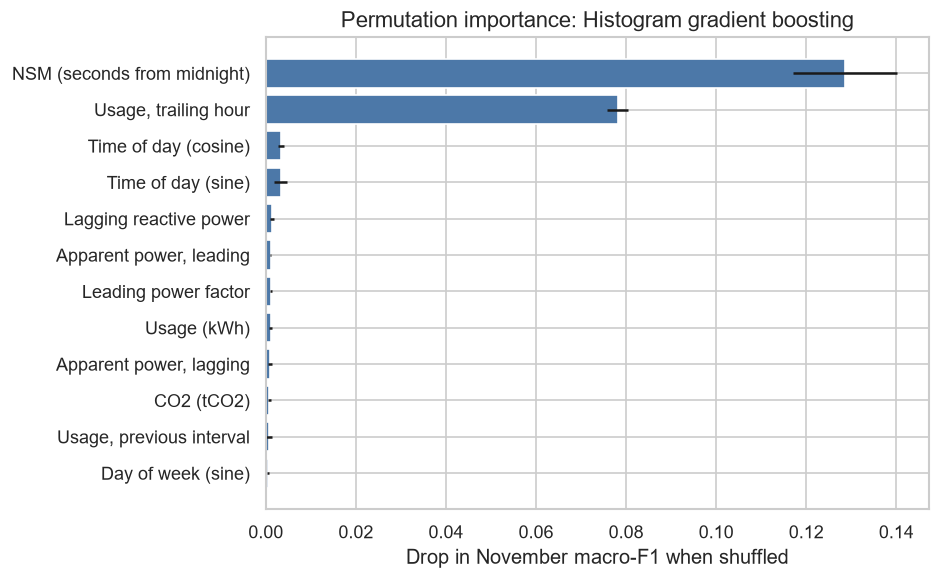

In [8]:
print("Refitting on January–November for the December comparison")
(final_train, final_test), train_medians = median_impute(train, [train, test])
assert not final_train[FEATURE_COLUMNS].isna().any().any()
assert not final_test[FEATURE_COLUMNS].isna().any().any()

december_rows = []
december_predictions = {}
for name in MODEL_NAMES:
    print(f"  fitting {name}")
    model = LoadModel(name)
    model.fit(final_train, final_train["Load_Type"])
    prediction = model.predict(final_test)
    scored = score_predictions(final_test["Load_Type"], prediction)
    scored["model"] = name
    scored["selected"] = name == chosen_name
    december_rows.append(scored)
    december_predictions[name] = prediction

december = pd.DataFrame(december_rows)
december.to_csv(OUTPUTS / "december_scores.csv", index=False)
print("December scores. The selected model was chosen before these numbers were computed:")
show_df(
    december[
        ["model", "selected", "accuracy", "macro_f1", "weighted_f1", "f1_light", "f1_medium", "f1_maximum"]
    ]
    .round(3)
    .reset_index(drop=True)
)

chosen_prediction = december_predictions[chosen_name]
y_december = final_test["Load_Type"]
print("December classification report for the selected model:")
print(classification_report(y_december, chosen_prediction, labels=LABELS, digits=3, zero_division=0))

chosen_november_model, november_frame, november_y = november_fitted[chosen_name]
if chosen_name == "Majority class":
    importance = pd.DataFrame(columns=["feature", "importance_mean", "importance_std"])
elif chosen_name == "Shallow decision tree":
    matrix = november_frame[TREE_COLUMNS]
    columns = TREE_COLUMNS
    estimator = chosen_november_model.model
elif chosen_name == "Logistic regression":
    matrix = chosen_november_model.scaler.transform(november_frame[FEATURE_COLUMNS])
    columns = FEATURE_COLUMNS
    estimator = chosen_november_model.model
else:
    matrix = november_frame[FEATURE_COLUMNS]
    columns = FEATURE_COLUMNS
    estimator = chosen_november_model.model

if chosen_name != "Majority class":
    print("Permutation importance on November")
    permuted = permutation_importance(
        estimator,
        matrix,
        november_y,
        scoring="f1_macro",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    importance = (
        pd.DataFrame(
            {
                "feature": columns,
                "importance_mean": permuted.importances_mean,
                "importance_std": permuted.importances_std,
            }
        )
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )
    importance.to_csv(OUTPUTS / "november_permutation_importance.csv", index=False)
    print("Features that move November macro-F1 when shuffled:")
    show_df(importance.head(12).round(4))

    top = importance.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(
        top["feature"].map(COLUMN_LABELS),
        top["importance_mean"],
        xerr=top["importance_std"],
        color="#4C78A8",
    )
    ax.set_xlabel("Drop in November macro-F1 when shuffled")
    ax.set_title(f"Permutation importance: {chosen_name}")
    save_figure(fig, FIGURES / "08_permutation_importance.png")

## 8. Where December still goes wrong

November macro-F1 is about 0.60, while September, October, and December are much higher. That gap matches the two weekday timetables in the training months. September and October keep the fall timetable the model has just seen. November is the first return to the winter timetable, and January is many months behind it, so the fall hours get applied to a winter month. December follows November. Once November is inside the training set, that winter timetable is available and the December score moves back up with September and October.

The choice stays the November winner. Balanced gradient boosting is about 0.001 higher on December, and that number was not allowed to change the selection.

The confusion matrix uses December only. The hour chart and the usage-band table use the original usage value, including a separate band for rows whose usage was blank before the median fill. Within a known season, medium and maximum occupy different hours, so those two classes are rarely swapped. The remaining mistakes are heavier classes predicted as light load, mostly where usage is under 10 kWh: the hour says medium or maximum, and the meter looks like a light interval.

,Predicted Light,Predicted Medium,Predicted Maximum
Actual Light,1727,6,11
Actual Medium,72,632,0
Actual Maximum,25,0,503


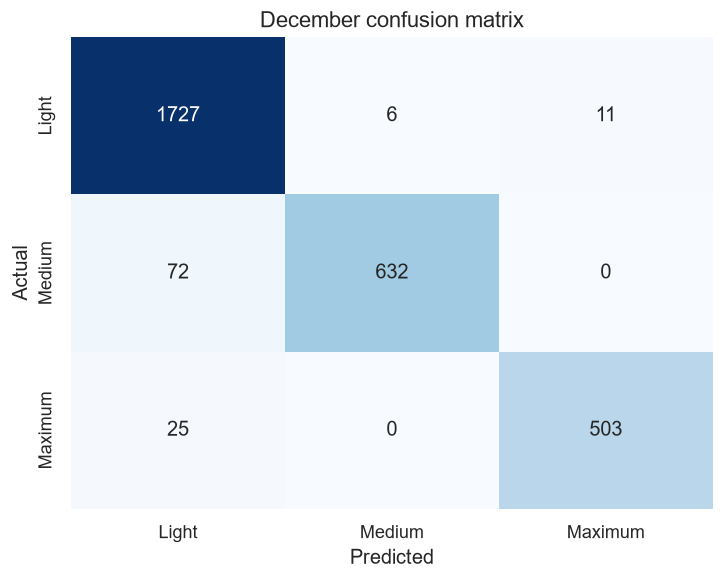

Medium/maximum swaps in December: 0


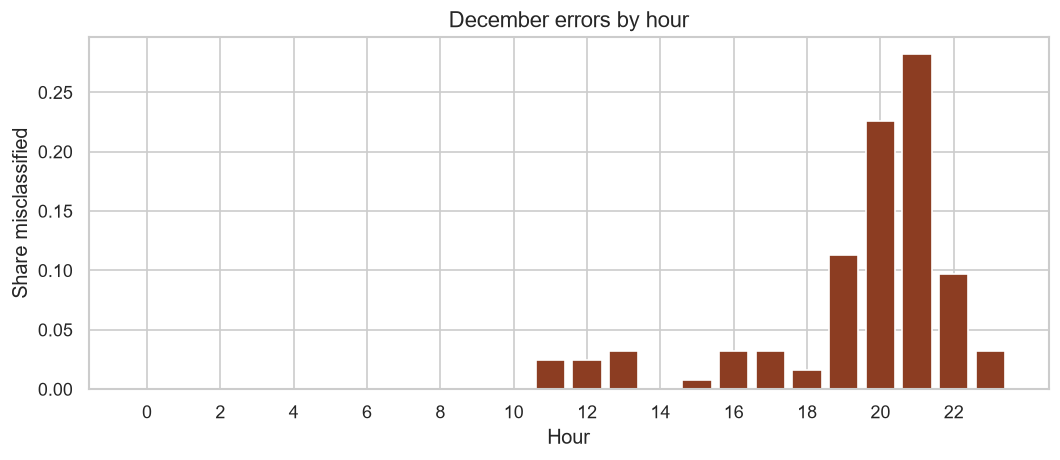

December errors by original usage band:


,usage_band,rows,error_rate,medium_maximum_swap_rate
0,0–10 kWh,1922,0.054,0.0
1,10–30 kWh,120,0.033,0.0
2,30–60 kWh,372,0.000,0.0
3,60–100 kWh,289,0.000,0.0
4,100+ kWh,110,0.000,0.0
5,Usage missing,163,0.037,0.0


The selected model is Histogram gradient boosting. It was chosen for November macro-F1 of 0.600, before December was scored. On December 2018 the accuracy is 0.962, the macro-F1 is 0.958, and the weighted F1 is 0.961. Per-class F1 is light 0.968, medium 0.942, and maximum 0.965. Always predicting the majority training class reaches accuracy 0.586 and macro-F1 0.246 on the same month. Medium and maximum are swapped on 0 December intervals. November is harder than September, October, or December because it is the first month back on the winter weekday timetable after the fall timetable. December follows that same winter timetable, so the score rises once November is in the training set. The balanced boosting model is slightly higher on December and was not selected, because the choice was locked on November. NSM was replaced from the timestamp. Power factor was replaced from the meter formula wherever usage and reactive power made that possible. Median fills and the model itself were fit

In [9]:
confusion = confusion_matrix(y_december, chosen_prediction, labels=LABELS)
confusion_frame = pd.DataFrame(
    confusion,
    index=[f"Actual {SHORT[label]}" for label in LABELS],
    columns=[f"Predicted {SHORT[label]}" for label in LABELS],
)
show_df(confusion_frame)
confusion_frame.to_csv(OUTPUTS / "december_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[SHORT[label] for label in LABELS],
    yticklabels=[SHORT[label] for label in LABELS],
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("December confusion matrix")
save_figure(fig, FIGURES / "06_confusion_matrix.png")

medium_maximum_swaps = int(confusion[1, 2] + confusion[2, 1])
print(f"Medium/maximum swaps in December: {medium_maximum_swaps}")

error_frame = final_test[["timestamp", "Usage_kWh", "hour"]].copy()
error_frame["actual"] = y_december.to_numpy()
error_frame["predicted"] = chosen_prediction
error_frame["wrong"] = error_frame["actual"] != error_frame["predicted"]
# The imputed frame replaced blank usage. Take the original blank-aware usage from `test`.
error_frame["usage_original"] = test["Usage_kWh"].to_numpy()

by_hour = error_frame.groupby("hour")["wrong"].mean().reindex(range(24))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.to_numpy(), color="#8C3D22")
ax.set_xlabel("Hour")
ax.set_ylabel("Share misclassified")
ax.set_title("December errors by hour")
ax.set_xticks(range(0, 24, 2))
save_figure(fig, FIGURES / "07_errors_by_hour.png")

usage_bands = pd.cut(
    error_frame["usage_original"],
    bins=[-0.01, 10, 30, 60, 100, np.inf],
    labels=["0–10 kWh", "10–30 kWh", "30–60 kWh", "60–100 kWh", "100+ kWh"],
)
error_frame["usage_band"] = usage_bands.astype(object)
error_frame.loc[error_frame["usage_original"].isna(), "usage_band"] = "Usage missing"
band_order = ["0–10 kWh", "10–30 kWh", "30–60 kWh", "60–100 kWh", "100+ kWh", "Usage missing"]
band_rows = []
for band in band_order:
    subset = error_frame.loc[error_frame["usage_band"] == band]
    if subset.empty:
        continue
    swap = (
        ((subset["actual"] == "Medium_Load") & (subset["predicted"] == "Maximum_Load"))
        | ((subset["actual"] == "Maximum_Load") & (subset["predicted"] == "Medium_Load"))
    )
    band_rows.append(
        {
            "usage_band": band,
            "rows": len(subset),
            "error_rate": subset["wrong"].mean(),
            "medium_maximum_swap_rate": swap.mean(),
        }
    )
band_table = pd.DataFrame(band_rows)
print("December errors by original usage band:")
show_df(band_table.round(3))
band_table.to_csv(OUTPUTS / "december_errors_by_usage.csv", index=False)

selected_row = december.loc[december["model"] == chosen_name].iloc[0]
majority_row = december.loc[december["model"] == "Majority class"].iloc[0]
summary = (
    f"The selected model is {chosen_name}. "
    f"It was chosen for November macro-F1 of {stability.loc[chosen_name, 'November']:.3f}, "
    f"before December was scored. "
    f"On December 2018 the accuracy is {selected_row['accuracy']:.3f}, "
    f"the macro-F1 is {selected_row['macro_f1']:.3f}, "
    f"and the weighted F1 is {selected_row['weighted_f1']:.3f}. "
    f"Per-class F1 is light {selected_row['f1_light']:.3f}, "
    f"medium {selected_row['f1_medium']:.3f}, "
    f"and maximum {selected_row['f1_maximum']:.3f}. "
    f"Always predicting the majority training class reaches accuracy {majority_row['accuracy']:.3f} "
    f"and macro-F1 {majority_row['macro_f1']:.3f} on the same month. "
    f"Medium and maximum are swapped on {medium_maximum_swaps} December intervals. "
    "November is harder than September, October, or December because it is the first month "
    "back on the winter weekday timetable after the fall timetable. "
    "December follows that same winter timetable, so the score rises once November is in the training set. "
    "The balanced boosting model is slightly higher on December and was not selected, "
    "because the choice was locked on November. "
    "NSM was replaced from the timestamp. Power factor was replaced from the meter formula "
    "wherever usage and reactive power made that possible. Median fills and the model itself "
    "were fit on January-November only."
)
print(summary)
(OUTPUTS / "summary.txt").write_text(summary + "\n", encoding="utf-8")
train_medians.rename("training_median").to_csv(OUTPUTS / "training_medians.csv")